# Developed Markets Equity Scorecard — **v2**
**US · Eurozone · UK · Switzerland · Japan** — relative 3–6 month outlook

## Why v2?
v1 (equal-weight, PMI/EPS/valuation/momentum) showed **no reliable edge**: composite IC ≈ 0, L/S Sharpe ≈ 0.05 (USD). Diagnosis (v1 notebook):
* **EPS revision** pillar has supporting evidence; **PMI change** had a *negative* IC; valuation and momentum were weak.
* Equal weights give the one working pillar only 25% of the vote and let the failing pillar subtract value.

## v2 changes — declared before running anything
| # | Change | Structural reason (not "to make the backtest look better") |
|---|---|---|
| **C1** | **Macro pillar: PMI 3M change → Financial-Conditions-Index (FCI) 3M easing**, scaled by each market's own history | PMI is a *coincident* activity gauge that is already public and largely priced; financial conditions are a *leading* driver of risk-asset returns and activity. FCI is in the supplied data. |
| **C2** | **Pillar weights: equal → walk-forward IC weights** (only past, already-realised information) | If pillars differ in reliability, weights should reflect *evidence available at the time*, not hindsight. Weight ∝ max(trailing mean IC, 0); equal weights until 36 realised IC observations exist. |

Everything else (data, window, price proxy, EPS / valuation / momentum signals, ranking, backtest mechanics) is **identical to v1**.

## ⚠ Research-integrity warning
v2 was designed **after seeing v1's results on this same history**, so there is **no untouched out-of-sample data**.
This is **CONTAMINATED OOS — v2 results are exploratory, not independent evidence.** To avoid hiding forking paths, the notebook runs and reports
**all four combinations** (v1, C1 only, C2 only, C1+C2) and lists them in a research ledger. **v2 headline = C1 + C2** (pre-declared).

## Research ledger
| Spec | Macro pillar | Pillar weights | Status |
|---|---|---|---|
| S0 = v1 | PMI change | equal | run, no edge |
| S1 | **FCI easing** | equal | run in this notebook |
| S2 | PMI change | **walk-forward IC** | run in this notebook |
| **S3 = v2** | **FCI easing** | **walk-forward IC** | run in this notebook — headline |

*Specifications examined on this data so far: 4. Significance statistics below are not adjusted for this and should be read as exploratory.*

## 0. Setup & parameters

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import spearmanr
from IPython.display import display, Markdown

pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.width = 200
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})

ROOT = Path('..').resolve()
RAW, DATA = ROOT/'data'/'raw', ROOT/'data'
OUT = ROOT/'output'/'v2'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)

COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']
# ---- unchanged from v1 ----
PMI_LAG, PMI_CHG, EPS_CHG, MIN_HIST, MOM_LOOK, MOM_SKIP = 1, 3, 3, 60, 12, 1
HORIZONS, H_SET, N_PERM, SEED = [3, 6], [1, 3, 6], 5000, 7
# ---- new in v2 ----
FCI_CHG   = 3     # C1: 3-month change in financial conditions (easing = positive)
MIN_FCI   = 36    # C1: min obs of the 3M-change history used to scale each market's FCI change
WF_H      = 3     # C2: IC horizon used for weights (3M, USD returns); IC of month s is "known" at s+3
MIN_IC    = 36    # C2: realised IC observations required before IC-weights are used (equal weights before)
PERM_SHARPE = 3000
PILLARS = {'pmi': 'Macro (v1): PMI 3M change', 'fci': 'Macro (v2): FCI 3M easing', 'micro': 'Micro: EPS 3M revision',
           'val': 'Valuation: fwd P/E z-score (inverted)', 'tech': 'Technical: 12-1M momentum'}
SPECS = {'S0 v1: PMI + equal wts':           (('pmi', 'micro', 'val', 'tech'), 'equal'),
         'S1: FCI + equal wts':              (('fci', 'micro', 'val', 'tech'), 'equal'),
         'S2: PMI + walk-fwd wts':           (('pmi', 'micro', 'val', 'tech'), 'wf'),
         'S3 v2: FCI + walk-fwd wts':        (('fci', 'micro', 'val', 'tech'), 'wf')}
HEAD = 'S3 v2: FCI + walk-fwd wts'; V1 = 'S0 v1: PMI + equal wts'

## 1. Data (same cleaning as v1, plus the FCI column)
FCI mapping (as assignment): US `GSFCI`, Eurozone `BFCIEU`, UK `GSGBFCI`, Switzerland `GSEAFCI` (euro-area proxy), Japan `GSJPFCI`.
**Sign check:** Goldman indices rise when conditions *tighten* (corr with VIX > 0); Bloomberg `BFCIEU` rises when conditions *ease* (corr with VIX < 0; crisis low −8.8).
We therefore define **easing = −ΔGS-FCI** and **easing = +ΔBFCI**.

In [2]:
SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', pmi='NAPMPMI Index',  fci=('GSFCI Index', -1),    fx=None),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    pmi='MPMIEZMA Index', fci=('BFCIEU Index', +1),   fx=('EURUSD BGN Curncy', 'direct')),
 'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    pmi='MPMIGBMA Index', fci=('GSGBFCI Index', -1),  fx=('GBPUSD BGN Curncy', 'direct')),
 'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    pmi='CH_PMI',         fci=('GSEAFCI Index', -1),  fx=('USDCHF Curncy', 'invert')),
 'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    pmi='JPYPMI',         fci=('GSJPFCI Index', -1),  fx=('USDJPY BGN Curncy', 'invert')),
}
PE_COL = 'BEst P/E Ratio'

def load_country(name, s):
    d = pd.read_excel(RAW/s['file']).dropna(subset=['Date']).copy()
    d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    d = d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')
    out = pd.DataFrame({'pe': d[PE_COL], 'eps': d[s['eps']], 'pmi': d[s['pmi']], 'fci_raw': d[s['fci'][0]]})
    out['fci_ease'] = s['fci'][1] * out['fci_raw']            # level oriented so that HIGHER = EASIER conditions
    if s['fx'] is None: out['fx'] = 1.0
    else:
        col, how = s['fx']; out['fx'] = d[col] if how == 'direct' else 1.0 / d[col]
    return out

frames = {c: load_country(c, SPEC[c]) for c in COUNTRIES}
PE, EPS, PMI, FX = [pd.DataFrame({c: frames[c][k] for c in COUNTRIES}) for k in ('pe', 'eps', 'pmi', 'fx')]
FCI_RAW, FCI_E = [pd.DataFrame({c: frames[c][k] for c in COUNTRIES}) for k in ('fci_raw', 'fci_ease')]
START = max(PE[c].first_valid_index() for c in COUNTRIES)
AS_OF = min(frames[c].index.max() for c in COUNTRIES)
for df in (PE, EPS, PMI, FX, FCI_RAW, FCI_E): df.drop(df.index[df.index > AS_OF], inplace=True)
win = pd.period_range(START, AS_OF, freq='M')
for df in (PE, EPS, PMI, FX, FCI_E): assert df.loc[win].notna().all().all()
print(f'Common window: {START} -> {AS_OF} ({len(win)} months); no missing values in P/E, EPS, PMI, FX, FCI.')

# sign verification against VIX (US file)
vix = pd.read_excel(RAW/'US_raw_data.xlsx').assign(m=lambda d: d.Date.dt.to_period('M')).set_index('m')['VIX Index']
chk = pd.DataFrame({c: [FCI_RAW[c].loc[win].corr(vix.loc[win]), FCI_E[c].loc[win].corr(vix.loc[win])] for c in COUNTRIES},
                   index=['corr(raw FCI, VIX)', 'corr(oriented "easing" FCI, VIX)']).T
display(chk.style.format('{:+.2f}'))
print('After orientation, higher FCI = easier conditions, so every market should correlate negatively with VIX.')

Common window: 2005-12 -> 2026-04 (245 months); no missing values in P/E, EPS, PMI, FX, FCI.


,"corr(raw FCI, VIX)","corr(oriented ""easing"" FCI, VIX)"
US,+0.48,-0.48
Eurozone,-0.75,-0.75
UK,+0.19,-0.19
Switzerland,+0.39,-0.39
Japan,+0.36,-0.36


After orientation, higher FCI = easier conditions, so every market should correlate negatively with VIX.


## 2. Implied price & returns (unchanged)

In [3]:
PX = PE * EPS; PX_USD = PX * FX
R_LOC, R_USD = PX.pct_change(), PX_USD.pct_change()
fwd = {('local', h): PX.shift(-h) / PX - 1 for h in HORIZONS}
fwd.update({('USD', h): PX_USD.shift(-h) / PX_USD - 1 for h in HORIZONS})

## 3. Signals
v1 signals unchanged. **New C1 signal:** `FCI easing` = (3M change in oriented FCI) ÷ (expanding std of that market's own 3M changes, ≥36 obs) —
the scaling makes Goldman and Bloomberg indices (very different units) comparable, and the cross-sectional z-score is then taken as for every other pillar.

In [4]:
def cs_z(df):
    ok = df.notna().all(axis=1)
    return df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1, ddof=1), axis=0).where(ok)

def build_raw_signals(PE, EPS, PMI, FCI_E, PX):
    dF = FCI_E.diff(FCI_CHG)
    return {
     'pmi':   PMI.shift(PMI_LAG) - PMI.shift(PMI_LAG + PMI_CHG),
     'fci':   dF / dF.expanding(MIN_FCI).std(),
     'micro': EPS / EPS.shift(EPS_CHG) - 1,
     'val':   -(PE - PE.expanding(MIN_HIST).mean()) / PE.expanding(MIN_HIST).std(),
     'tech':  PX.shift(MOM_SKIP) / PX.shift(MOM_LOOK) - 1,
    }
RAW_SIG = build_raw_signals(PE, EPS, PMI, FCI_E, PX)
Z = {k: cs_z(v.loc[win]) for k, v in RAW_SIG.items()}
SIG_START = max(z.dropna().index.min() for z in Z.values())
Z = {k: z.loc[SIG_START:] for k, z in Z.items()}
SIG_IDX = Z['pmi'].index
print(f'Scorecard window: {SIG_IDX[0]} -> {SIG_IDX[-1]} ({len(SIG_IDX)} months) — same window as v1 (valuation is the binding constraint).')

Scorecard window: 2010-11 -> 2026-04 (186 months) — same window as v1 (valuation is the binding constraint).


## 4. Predictive power of the new macro signal (vs the PMI it replaces)
Same tests as v1: cross-sectional rank IC, top-2 minus bottom-2 spread, Newey-West t-stat (lags = h), one-sided block-permutation p-value (blocks of h months).

In [5]:
def rank_ic(sig, f):
    idx = sig.index.intersection(f.dropna().index)
    s, r = sig.loc[idx].rank(axis=1), f.loc[idx].rank(axis=1)
    s, r = s.sub(s.mean(axis=1), axis=0), r.sub(r.mean(axis=1), axis=0)
    return (s * r).sum(axis=1) / np.sqrt((s**2).sum(axis=1) * (r**2).sum(axis=1))

def top_bottom_spread(sig, f):
    idx = sig.index.intersection(f.dropna().index)
    rk = sig.loc[idx].rank(axis=1)
    return f.loc[idx].where(rk >= 4).mean(axis=1) - f.loc[idx].where(rk <= 2).mean(axis=1)

def nw_t(x, lags):
    x = x.dropna()
    return float(sm.OLS(x.values, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}).tvalues[0])

def block_perm_p(sig, f, h, n_perm=N_PERM, seed=SEED):
    idx = sig.index.intersection(f.dropna().index)
    S = sig.loc[idx].rank(axis=1).to_numpy(copy=True); F = f.loc[idx].rank(axis=1).to_numpy(copy=True)
    S = S - S.mean(1, keepdims=True); F = F - F.mean(1, keepdims=True)
    denom = np.sqrt((S**2).sum(1) * (F**2).sum(1)); obs = ((S * F).sum(1) / denom).mean()
    T = len(idx); blk = np.arange(T) // h; B = blk.max() + 1
    perms = np.argsort(np.random.default_rng(seed).random((n_perm, B, S.shape[1])), axis=2)[:, blk, :]
    Sp = np.take_along_axis(np.broadcast_to(S, (n_perm,) + S.shape), perms, axis=2)
    null = ((Sp * F).sum(2) / denom).mean(1)
    return (np.sum(null >= obs) + 1) / (n_perm + 1)

def pp_rows(name, sig):
    rows = []
    for basis in ('local', 'USD'):
        for h in HORIZONS:
            f = fwd[(basis, h)]; ic = rank_ic(sig, f); sp = top_bottom_spread(sig, f); half = len(ic) // 2
            rows.append({'Signal': name, 'Basis': basis, 'Horizon (M)': h, 'N months': len(ic), 'Mean IC': ic.mean(),
                         'IC t-stat (NW)': nw_t(ic, h), 'IC hit-rate': (ic > 0).mean(), 'IC 1st half': ic.iloc[:half].mean(),
                         'IC 2nd half': ic.iloc[half:].mean(), 'Top2-Bottom2 spread %': sp.mean() * 100,
                         'Spread t-stat (NW)': nw_t(sp, h), 'Perm p-value (1-sided)': block_perm_p(sig, f, h)})
    return rows

PP_single = pd.DataFrame([r for k in PILLARS for r in pp_rows(PILLARS[k], Z[k])])
fmt_pp = {'Mean IC': '{:.3f}', 'IC t-stat (NW)': '{:.2f}', 'IC hit-rate': '{:.0%}', 'IC 1st half': '{:.3f}', 'IC 2nd half': '{:.3f}',
          'Top2-Bottom2 spread %': '{:.2f}', 'Spread t-stat (NW)': '{:.2f}', 'Perm p-value (1-sided)': '{:.3f}'}
display(PP_single.set_index(['Signal', 'Basis', 'Horizon (M)']).style.format(fmt_pp))

## 5. C2 — Walk-forward pillar weights
For each month *t* and pillar *k*:
1. Pillar rank-IC at month *s* is computed against the 3M forward USD return; it is **only known at s+3**.
2. At *t* use the expanding mean of all ICs with *s ≤ t−3* (≥ 36 observations; before that → equal weights).
3. Weight ∝ max(mean IC, 0), normalised to 100%; if no pillar has positive evidence → equal weights.

No future information enters a weight. The only free choices (3M/USD basis, 36-month minimum) are fixed here and not tuned.

Walk-forward IC weights become active from 2014-01 (first 36 realised ICs required); equal weights before that.


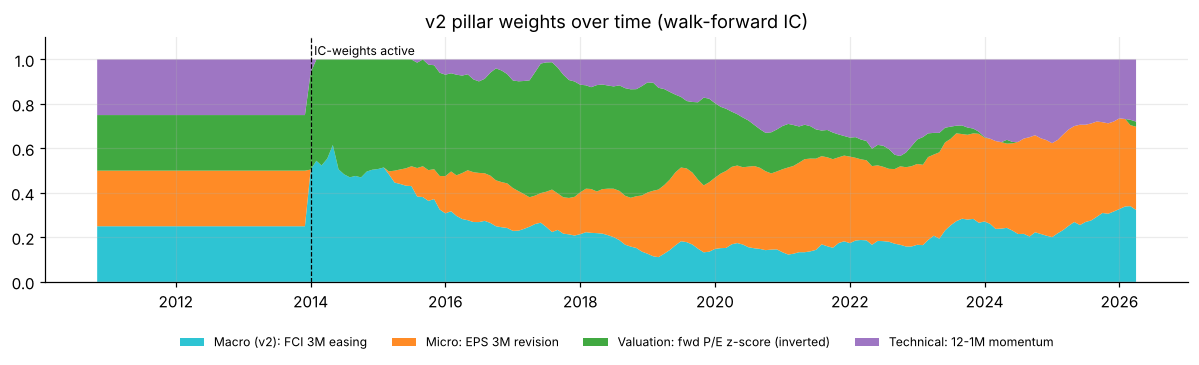

,fci,micro,val,tech
2010-11,25%,25%,25%,25%
2021-05,13%,42%,15%,29%
2024-05,24%,38%,2%,36%
2026-04,32%,37%,2%,28%


In [6]:
def wf_weights(Zd, keys, f3):
    ic = pd.DataFrame({k: rank_ic(Zd[k], f3) for k in keys}).reindex(SIG_IDX)
    m = ic.shift(WF_H).expanding(min_periods=MIN_IC).mean()           # IC of month s is known at s+WF_H
    pos = m.clip(lower=0); tot = pos.sum(axis=1)
    w = pos.div(tot.replace(0, np.nan), axis=0).fillna(1 / len(keys))
    active = m.notna().all(axis=1) & (tot > 0)
    return w, m, active

def composite(Zd, keys, w=None):
    if w is None: return sum(Zd[k] for k in keys) / len(keys)
    return sum(Zd[k].mul(w[k], axis=0) for k in keys)

F3U = fwd[('USD', WF_H)]
WTS, COMPS, WF_STATE = {}, {}, {}
for name, (keys, mode) in SPECS.items():
    if mode == 'equal':
        COMPS[name] = composite(Z, keys)
    else:
        w, m, active = wf_weights(Z, keys, F3U); WTS[name] = w; WF_STATE[name] = (m, active)
        COMPS[name] = composite(Z, keys, w)
WF_START = WF_STATE[HEAD][1][WF_STATE[HEAD][1]].index.min()
print(f'Walk-forward IC weights become active from {WF_START} (first {MIN_IC} realised ICs required); equal weights before that.')

w3 = WTS[HEAD]
fig, ax = plt.subplots(figsize=(11, 3.6))
cols_ = {'fci': '#17becf', 'micro': '#ff7f0e', 'val': '#2ca02c', 'tech': '#9467bd', 'pmi': '#1f77b4'}
ax.stackplot(w3.index.to_timestamp(), [w3[k] for k in w3.columns], labels=[PILLARS[k] for k in w3.columns], colors=[cols_[k] for k in w3.columns], alpha=.9)
ax.axvline(WF_START.to_timestamp(), color='k', ls='--', lw=.8); ax.text(WF_START.to_timestamp(), 1.02, ' IC-weights active', fontsize=8)
ax.set_ylim(0, 1.1); ax.set_title('v2 pillar weights over time (walk-forward IC)'); ax.legend(fontsize=8, ncol=4, loc='lower center', bbox_to_anchor=(.5, -.32), frameon=False)
plt.tight_layout(); plt.savefig(CH/'fig_v2_weights.png', dpi=200, bbox_inches='tight'); plt.show()
display(w3.iloc[[0, -60, -24, -1]].style.format('{:.0%}'))

## 6. Predictive power of the full composites (all four specifications)

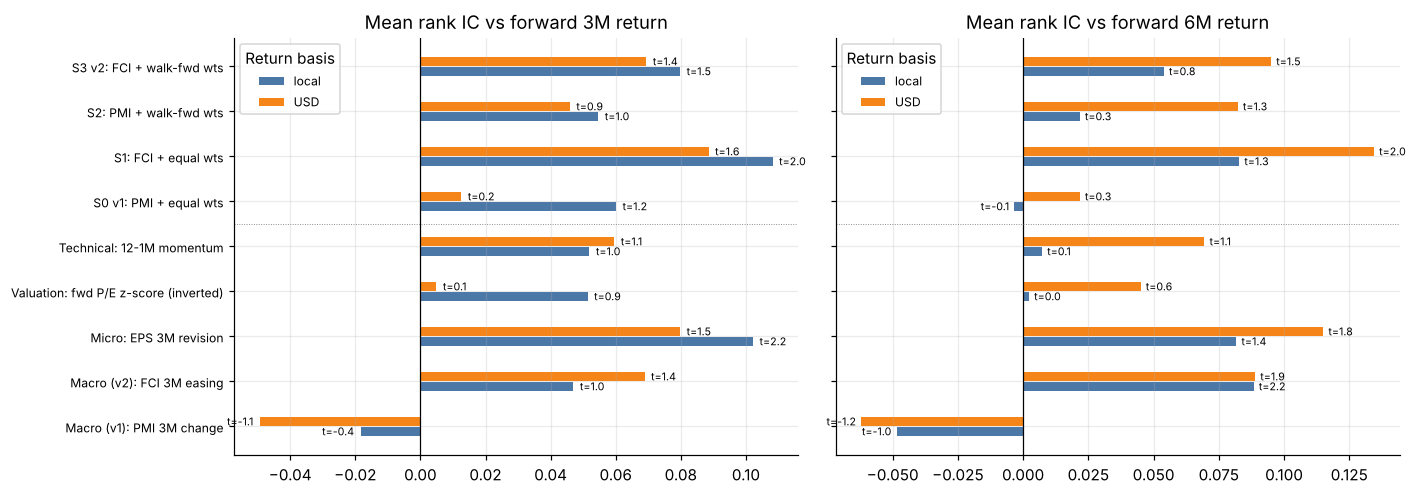

In [7]:
PP_comp = pd.DataFrame([r for name, c in COMPS.items() for r in pp_rows(name, c)])
display(PP_comp.set_index(['Signal', 'Basis', 'Horizon (M)']).style.format(fmt_pp))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
allnames = [PILLARS[k] for k in PILLARS] + list(SPECS)
PPall = pd.concat([PP_single, PP_comp]); y = np.arange(len(allnames)); w_ = 0.2
for ax, h in zip(axes, HORIZONS):
    for i, basis in enumerate(('local', 'USD')):
        d = PPall[(PPall['Horizon (M)'] == h) & (PPall.Basis == basis)].set_index('Signal').loc[allnames]
        yy = y + (i - .5) * w_ * 1.1
        ax.barh(yy, d['Mean IC'], height=w_, label=basis, color=['#4c78a8', '#f58518'][i])
        for y_, ic_, t_ in zip(yy, d['Mean IC'], d['IC t-stat (NW)']):
            ax.text(ic_ + (0.002 if ic_ >= 0 else -0.002), y_, f't={t_:.1f}', va='center', ha='left' if ic_ >= 0 else 'right', fontsize=7)
    ax.axvline(0, color='k', lw=.8); ax.axhline(4.5, color='grey', lw=.6, ls=':'); ax.set_title(f'Mean rank IC vs forward {h}M return')
    ax.set_yticks(y); ax.set_yticklabels(allnames, fontsize=8); ax.invert_yaxis(); ax.legend(title='Return basis', fontsize=8)
plt.tight_layout(); plt.savefig(CH/'fig_v2_predictive_power.png', dpi=200, bbox_inches='tight'); plt.show()

## 7. Backtest (mechanics identical to v1)
Score at *t* → positions earned *t → t+1*; gross of costs; score-weighted dollar-neutral L/S (longs +100% / shorts −100%) and long-only top-2 vs equal-weight benchmark;
holding horizon H = average of the last H monthly weight sets (H = 3 headline). Local and USD.

In [8]:
def base_w_ls(score): return score.div(score.clip(lower=0).sum(axis=1), axis=0)
def base_w_lo(score): return (score.rank(axis=1, ascending=False) <= 2).astype(float) / 2
def held(wb, H): return wb.rolling(H, min_periods=1).mean()
def port_ret(w, r):
    ww = w.shift(1).dropna(how='any'); return (ww * r.reindex(ww.index)).sum(axis=1, min_count=1)
def max_dd(r):
    cum = (1 + r).cumprod(); return (cum / cum.cummax() - 1).min()
def stats(r, turnover=None, active=False):
    n = len(r); ann = (1 + r).prod() ** (12 / n) - 1; vol = r.std() * np.sqrt(12)
    d = {'Ann. return': ann, 'Ann. vol': vol, ('Info ratio' if active else 'Sharpe'): r.mean() * 12 / vol,
         'Max drawdown': max_dd(r), 'Hit rate (months)': (r > 0).mean(), 'Worst month': r.min()}
    if turnover is not None:
        d['Annual turnover (x)'] = turnover * 12; d['Break-even cost (bps)'] = ann / (turnover * 12) * 1e4 if turnover > 0 else np.nan
    return d

EW = pd.DataFrame(0.2, index=SIG_IDX, columns=COUNTRIES)
BT, ROWS = {}, []
for name, comp in COMPS.items():
    for basis, R in (('local', R_LOC), ('USD', R_USD)):
        for H in H_SET:
            w_ls, w_lo = held(base_w_ls(comp), H), held(base_w_lo(comp), H)
            r_ls, r_lo, r_bm = port_ret(w_ls, R), port_ret(w_lo, R), port_ret(EW, R)
            BT[(name, basis, H)] = pd.DataFrame({'LS': r_ls, 'LongOnly_top2': r_lo, 'EW_benchmark': r_bm, 'Active': r_lo - r_bm})
            to_ls, to_lo = w_ls.diff().abs().sum(axis=1).iloc[1:].mean(), w_lo.diff().abs().sum(axis=1).iloc[1:].mean()
            ROWS.append({'Spec': name, 'Strategy': 'A. Score-weighted L/S', 'Basis': basis, 'H (M)': H, **stats(r_ls, to_ls)})
            ROWS.append({'Spec': name, 'Strategy': 'B. Long-only top-2 (absolute)', 'Basis': basis, 'H (M)': H, **stats(r_lo, to_lo)})
            ROWS.append({'Spec': name, 'Strategy': 'B. Top-2 minus EW benchmark (active)', 'Basis': basis, 'H (M)': H, **stats(r_lo - r_bm, to_lo, active=True)})
            ROWS.append({'Spec': name, 'Strategy': 'Benchmark: EW 5 markets', 'Basis': basis, 'H (M)': H, **stats(r_bm)})
STATS = pd.DataFrame(ROWS)
fmt = {'Ann. return': '{:.1%}', 'Ann. vol': '{:.1%}', 'Sharpe': '{:.2f}', 'Info ratio': '{:.2f}', 'Max drawdown': '{:.1%}',
       'Hit rate (months)': '{:.0%}', 'Worst month': '{:.1%}', 'Annual turnover (x)': '{:.1f}', 'Break-even cost (bps)': '{:.0f}'}
bt_idx = BT[(HEAD, 'USD', 3)].dropna().index; bt_start, bt_end = bt_idx[0], bt_idx[-1]
print(f'Backtest window: {bt_start} -> {bt_end} ({len(bt_idx)} months)')
display(STATS[(STATS.Spec == HEAD)].drop(columns='Spec').set_index(['Strategy', 'Basis', 'H (M)']).style.format(fmt, na_rep='–'))

Backtest window: 2010-12 -> 2026-04 (185 months)


,,,Ann. return,Ann. vol,Sharpe,Max drawdown,Hit rate (months),Worst month,Annual turnover (x),Break-even cost (bps),Info ratio
Strategy,Basis,H (M),,,,,,,,,
A. Score-weighted L/S,local,1,2.4%,9.2%,0.31,-21.8%,56%,-6.8%,12.2,20,–
B. Long-only top-2 (absolute),local,1,8.5%,12.6%,0.71,-23.3%,64%,-9.0%,5.0,170,–
B. Top-2 minus EW benchmark (active),local,1,0.8%,4.5%,–,-12.8%,50%,-3.7%,5.0,16,0.20
Benchmark: EW 5 markets,local,1,7.6%,11.9%,0.67,-20.2%,66%,-11.4%,–,–,–
A. Score-weighted L/S,local,3,2.1%,8.8%,0.28,-28.8%,53%,-7.3%,7.0,30,–
B. Long-only top-2 (absolute),local,3,8.7%,12.3%,0.74,-21.0%,64%,-8.6%,2.7,325,–
B. Top-2 minus EW benchmark (active),local,3,1.0%,3.9%,–,-16.0%,49%,-3.3%,2.7,38,0.28
Benchmark: EW 5 markets,local,3,7.6%,11.9%,0.67,-20.2%,66%,-11.4%,–,–,–
A. Score-weighted L/S,local,6,2.1%,8.2%,0.29,-24.5%,51%,-6.8%,3.9,53,–


### Specification comparison (L/S, H = 3M) — full window and the "walk-forward active" sub-window
The sub-window starts when IC weights switch on, so S0/S1 (equal weights) and S2/S3 are compared on exactly the same months.

In [9]:
def spec_table(sub=None):
    rows = []
    for name in SPECS:
        r = {'Spec': name}
        for basis in ('USD', 'local'):
            x = BT[(name, basis, 3)]['LS'].dropna(); x = x if sub is None else x[x.index >= sub]
            s = stats(x); r[f'Sharpe {basis}'] = s['Sharpe']; r[f'Ann.ret {basis}'] = s['Ann. return']; r[f'MaxDD {basis}'] = s['Max drawdown']
        xa = BT[(name, 'USD', 3)]['Active'].dropna(); xa = xa if sub is None else xa[xa.index >= sub]
        r['Active IR (top2-EW, USD)'] = xa.mean() * 12 / (xa.std() * np.sqrt(12))
        rows.append(r)
    return pd.DataFrame(rows).set_index('Spec')
fm = {c: ('{:.1%}' if ('ret' in c or 'DD' in c) else '{:.2f}') for c in spec_table().columns}
print('FULL WINDOW', bt_start, '->', bt_end); display(spec_table().style.format(fm))
print('WALK-FORWARD ACTIVE WINDOW', WF_START + 1, '->', bt_end); display(spec_table(WF_START + 1).style.format(fm))

FULL WINDOW 2010-12 -> 2026-04


,Sharpe USD,Ann.ret USD,MaxDD USD,Sharpe local,Ann.ret local,MaxDD local,"Active IR (top2-EW, USD)"
Spec,,,,,,,
S0 v1: PMI + equal wts,0.05,0.1%,-26.9%,0.21,1.5%,-19.5%,-0.19
S1: FCI + equal wts,0.35,2.6%,-21.6%,0.38,3.1%,-25.7%,0.53
S2: PMI + walk-fwd wts,0.10,0.4%,-21.4%,0.17,1.1%,-27.4%,0.01
S3 v2: FCI + walk-fwd wts,0.18,1.1%,-21.8%,0.28,2.1%,-28.8%,0.21


WALK-FORWARD ACTIVE WINDOW 2014-02 -> 2026-04


,Sharpe USD,Ann.ret USD,MaxDD USD,Sharpe local,Ann.ret local,MaxDD local,"Active IR (top2-EW, USD)"
Spec,,,,,,,
S0 v1: PMI + equal wts,0.03,-0.1%,-26.9%,0.20,1.3%,-19.5%,-0.14
S1: FCI + equal wts,0.30,2.0%,-21.6%,0.25,1.8%,-25.7%,0.43
S2: PMI + walk-fwd wts,0.08,0.4%,-21.4%,0.14,0.9%,-27.4%,0.12
S3 v2: FCI + walk-fwd wts,0.07,0.2%,-21.8%,0.11,0.6%,-28.8%,0.03


### Is the headline Sharpe distinguishable from luck? (block-permutation null on the strategy itself)
Country labels of the composite are shuffled in 3-month blocks (keeps persistence and tranche overlap), 3,000 draws, one-sided p-value for the L/S Sharpe.
**Four specifications were examined, so p-values are not adjusted — treat as exploratory.**

In [10]:
def sharpe_perm(comp, R, H=3, block=3, n_perm=PERM_SHARPE, seed=SEED):
    W = base_w_ls(comp).to_numpy(); Rm = R.reindex(comp.index).to_numpy(); T = W.shape[0]
    blk = np.arange(T) // block; B = blk.max() + 1
    perms = np.argsort(np.random.default_rng(seed).random((n_perm, B, W.shape[1])), axis=2)[:, blk, :]
    def run(Wp):                                   # Wp: (P, T, N) base weights -> annualised Sharpe of the H-tranche L/S per draw
        cs = np.cumsum(Wp, axis=1); lag = np.zeros_like(cs); lag[:, H:, :] = cs[:, :-H, :]
        hd = (cs - lag) / np.minimum(np.arange(T) + 1, H)[None, :, None]
        ret = (hd[:, :-1, :] * Rm[None, 1:, :]).sum(-1)       # weights at t earn the return of t+1
        return ret.mean(1) / ret.std(1, ddof=1) * np.sqrt(12)
    obs = run(W[None])[0]; null = run(np.take_along_axis(np.broadcast_to(W, (n_perm,) + W.shape), perms, axis=2))
    return obs, (np.sum(null >= obs) + 1) / (n_perm + 1), np.percentile(null, [50, 95, 99])

perm_rows = []
for name, comp in COMPS.items():
    for basis, R in (('USD', R_USD), ('local', R_LOC)):
        obs, p, q = sharpe_perm(comp, R)
        chk_ = stats(BT[(name, basis, 3)]['LS'].dropna())['Sharpe']; assert abs(obs - chk_) < 1e-9, (obs, chk_)   # same number as the backtest
        perm_rows.append({'Spec': name, 'Basis': basis, 'Observed Sharpe (L/S, H=3)': obs, 'Null median': q[0], 'Null 95th pct': q[1], 'Null 99th pct': q[2], 'Perm p (1-sided)': p})
PERM = pd.DataFrame(perm_rows)
display(PERM.set_index(['Spec', 'Basis']).style.format('{:.2f}', subset=PERM.columns[2:6]).format('{:.3f}', subset=['Perm p (1-sided)']))

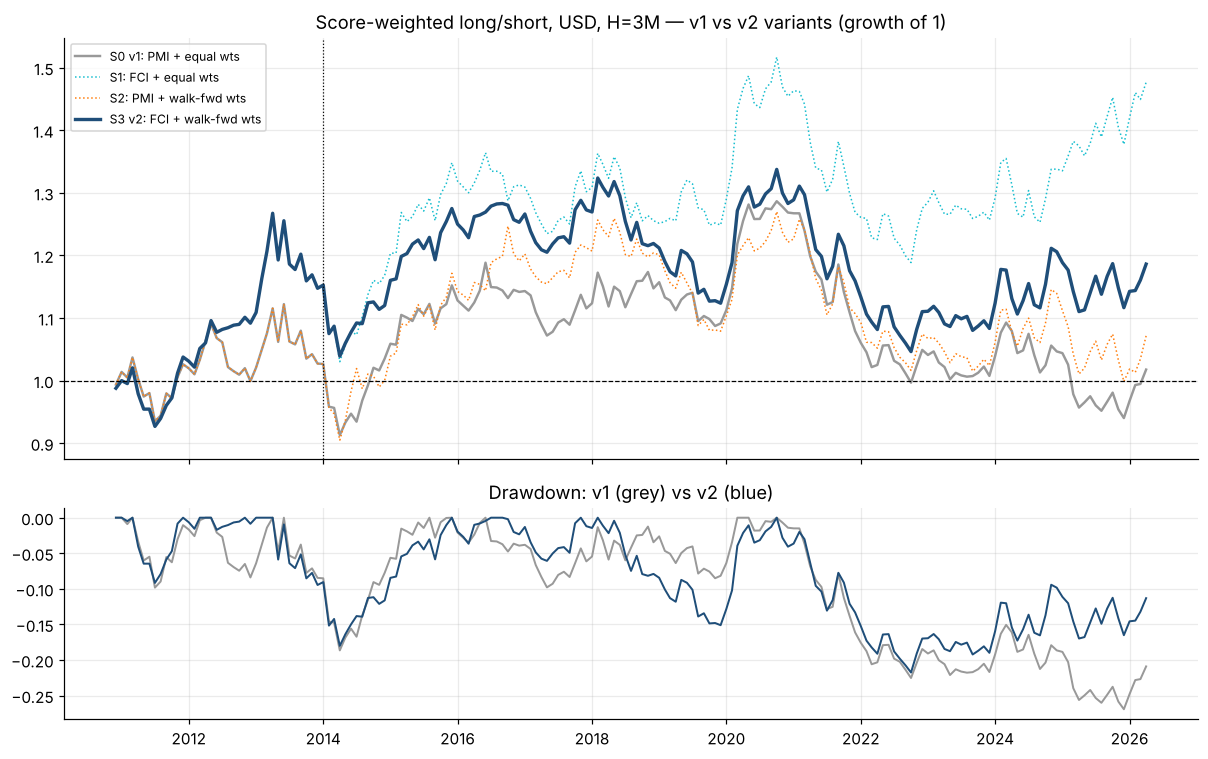

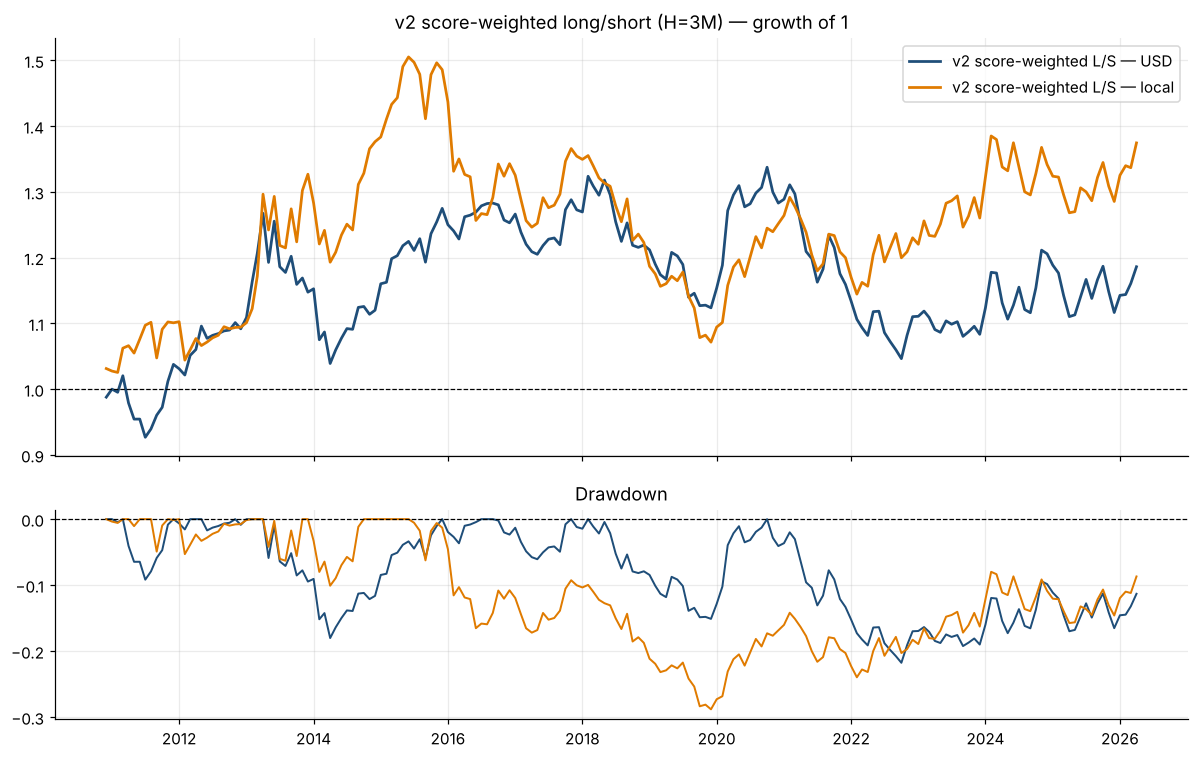

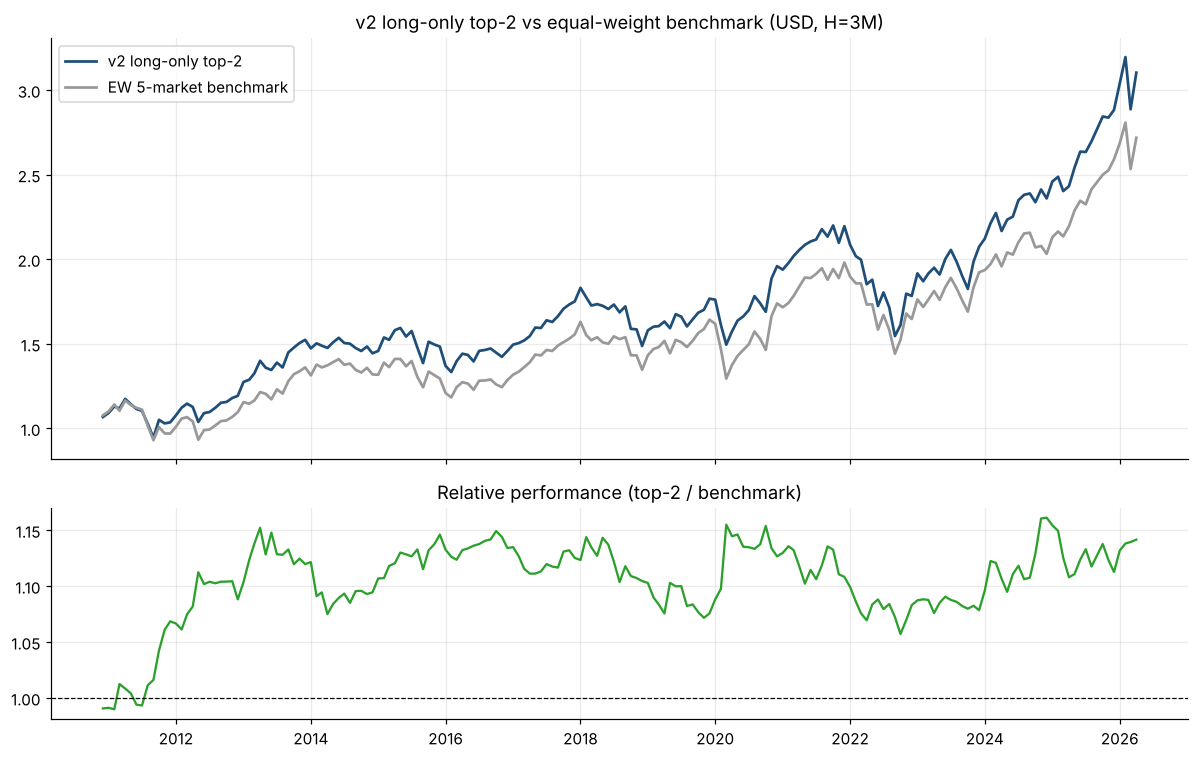

In [11]:
H0 = 3
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
styles = {V1: ('#999999', 1.6, '-'), 'S1: FCI + equal wts': ('#17becf', 1.0, ':'), 'S2: PMI + walk-fwd wts': ('#ff7f0e', 1.0, ':'), HEAD: ('#1f4e79', 2.2, '-')}
for name, (c_, lw_, ls_) in styles.items():
    r = BT[(name, 'USD', H0)]['LS'].dropna(); cum = (1 + r).cumprod()
    ax[0].plot(cum.index.to_timestamp(), cum, color=c_, lw=lw_, ls=ls_, label=name)
    if name in (V1, HEAD): ax[1].plot(cum.index.to_timestamp(), cum / cum.cummax() - 1, color=c_, lw=1.3)
ax[0].axhline(1, color='k', ls='--', lw=.8); ax[0].axvline(WF_START.to_timestamp(), color='k', ls=':', lw=.8)
ax[0].set_title('Score-weighted long/short, USD, H=3M — v1 vs v2 variants (growth of 1)'); ax[0].legend(fontsize=8); ax[1].set_title('Drawdown: v1 (grey) vs v2 (blue)')
plt.tight_layout(); plt.savefig(CH/'fig_v2_bt_compare.png', dpi=200, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for basis, col in (('USD', '#1f4e79'), ('local', '#e07b00')):
    r = BT[(HEAD, basis, H0)]['LS'].dropna(); cum = (1 + r).cumprod()
    ax[0].plot(cum.index.to_timestamp(), cum, color=col, label=f'v2 score-weighted L/S — {basis}', lw=1.8); ax[1].plot(cum.index.to_timestamp(), cum / cum.cummax() - 1, color=col, lw=1.3)
ax[0].axhline(1, color='k', ls='--', lw=.8); ax[0].set_title(f'v2 score-weighted long/short (H={H0}M) — growth of 1'); ax[0].legend(); ax[1].set_title('Drawdown'); ax[1].axhline(0, color='k', ls='--', lw=.8)
plt.tight_layout(); plt.savefig(CH/'fig_v2_bt_longshort.png', dpi=200, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
d = BT[(HEAD, 'USD', H0)].dropna()
for col, lab, c in (('LongOnly_top2', 'v2 long-only top-2', '#1f4e79'), ('EW_benchmark', 'EW 5-market benchmark', '#999999')):
    cum = (1 + d[col]).cumprod(); ax[0].plot(cum.index.to_timestamp(), cum, label=lab, color=c, lw=1.8)
ax[0].set_title(f'v2 long-only top-2 vs equal-weight benchmark (USD, H={H0}M)'); ax[0].legend()
rel = (1 + d['LongOnly_top2']).cumprod() / (1 + d['EW_benchmark']).cumprod()
ax[1].plot(rel.index.to_timestamp(), rel, color='#2ca02c', lw=1.5); ax[1].axhline(1, color='k', ls='--', lw=.8); ax[1].set_title('Relative performance (top-2 / benchmark)')
plt.tight_layout(); plt.savefig(CH/'fig_v2_bt_longonly.png', dpi=200, bbox_inches='tight'); plt.show()

### Adversarial checks on v2 (H = 3M, USD L/S)

In [12]:
r = BT[(HEAD, 'USD', H0)]['LS'].dropna()
yr = r.groupby(r.index.year).apply(lambda x: (1 + x).prod() - 1)
print('Calendar-year return:'); display(yr.to_frame('v2').join(BT[(V1, 'USD', H0)]['LS'].dropna().groupby(lambda i: i.year).apply(lambda x: (1 + x).prod() - 1).rename('v1')).T.style.format('{:.1%}'))
print(f'Sum of monthly returns = {r.sum():.1%}; best 5 months add {r.nlargest(5).sum():.1%}; worst 5 months subtract {r.nsmallest(5).sum():.1%}')
half = len(r) // 2
sh = lambda x: x.mean() * 12 / (x.std() * np.sqrt(12))
print(f'Sharpe  1st half: {sh(r.iloc[:half]):.2f}   2nd half: {sh(r.iloc[half:]):.2f}')
lo_rows = []
for drop in COUNTRIES:
    keep = [c for c in COUNTRIES if c != drop]; Zk = {k: cs_z(RAW_SIG[k].loc[SIG_IDX, keep]) for k in PILLARS}
    keys = SPECS[HEAD][0]
    ic3 = pd.DataFrame({k: rank_ic(Zk[k], F3U[keep]) for k in keys}).reindex(SIG_IDX)   # weights re-derived on the 4 remaining markets
    mk = ic3.shift(WF_H).expanding(min_periods=MIN_IC).mean().clip(lower=0); tot = mk.sum(axis=1)
    wk = mk.div(tot.replace(0, np.nan), axis=0).fillna(1 / len(keys))
    ck = sum(Zk[k].mul(wk[k], axis=0) for k in keys)
    rr = port_ret(held(base_w_ls(ck), H0), R_USD[keep]).dropna()
    lo_rows.append({'Dropped market': drop, 'Ann. return': (1 + rr).prod() ** (12 / len(rr)) - 1, 'Sharpe': sh(rr), 'Max drawdown': max_dd(rr)})
display(pd.DataFrame(lo_rows).set_index('Dropped market').style.format({'Ann. return': '{:.1%}', 'Sharpe': '{:.2f}', 'Max drawdown': '{:.1%}'}))

Calendar-year return:


,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
v2,-1.2%,5.0%,5.2%,5.1%,-2.4%,13.8%,-1.7%,1.6%,-4.2%,-7.8%,14.2%,-9.6%,-4.2%,-2.4%,11.3%,-7.4%,6.2%
v1,-0.6%,3.3%,-2.6%,2.8%,0.8%,11.3%,-0.9%,-2.3%,2.9%,-4.9%,16.2%,-14.9%,-2.8%,-4.0%,3.9%,-10.2%,8.2%


Sum of monthly returns = 22.0%; best 5 months add 27.1%; worst 5 months subtract -26.7%
Sharpe  1st half: 0.41   2nd half: -0.05


,Ann. return,Sharpe,Max drawdown
Dropped market,,,
US,-0.6%,-0.03,-33.0%
Eurozone,2.5%,0.33,-18.9%
UK,1.3%,0.20,-23.5%
Switzerland,0.9%,0.14,-30.9%
Japan,4.7%,0.63,-15.8%


### Integrity checks (re-computation + look-ahead test, including the walk-forward weights)

In [13]:
t = pd.Period('2018-05', 'M')
assert abs(spearmanr(COMPS[HEAD].loc[t], fwd[('USD', 3)].loc[t]).statistic - rank_ic(COMPS[HEAD], fwd[('USD', 3)]).loc[t]) < 1e-12
rr1 = port_ret(held(base_w_ls(COMPS[HEAD]), 1), R_LOC)
for t in [pd.Period(x, 'M') for x in ('2012-03', '2016-09', '2020-04', '2025-11')]:
    w = COMPS[HEAD].loc[t - 1] / COMPS[HEAD].loc[t - 1].clip(lower=0).sum()
    assert abs((w * R_LOC.loc[t]).sum() - rr1.loc[t]) < 1e-12 and abs(w.sum()) < 1e-12 and abs(w.abs().sum() - 2) < 1e-12
# look-ahead: rebuild signals, IC weights and composite using ONLY data up to T (forward returns beyond T are unknown) and compare with the full run
for T in [pd.Period('2017-06', 'M'), pd.Period('2022-09', 'M')]:
    rs = build_raw_signals(PE.loc[:T], EPS.loc[:T], PMI.loc[:T], FCI_E.loc[:T], PX.loc[:T])
    Zt = {k: cs_z(v.loc[win[win <= T]]) for k, v in rs.items()}
    f3t = PX_USD.loc[:T].shift(-WF_H) / PX_USD.loc[:T] - 1
    keys = SPECS[HEAD][0]; idx_t = SIG_IDX[SIG_IDX <= T]
    ic = pd.DataFrame({k: rank_ic(Zt[k], f3t) for k in keys}).reindex(idx_t)
    m = ic.shift(WF_H).expanding(min_periods=MIN_IC).mean().clip(lower=0); tot = m.sum(axis=1)
    wt = m.div(tot.replace(0, np.nan), axis=0).fillna(1 / len(keys))
    ct = sum(Zt[k].loc[idx_t].mul(wt[k], axis=0) for k in keys)
    assert np.allclose(ct.loc[T].values, COMPS[HEAD].loc[T].values), T
    assert np.allclose(wt.loc[T].values, WTS[HEAD].loc[T].values), T
print('All integrity checks passed: IC matches scipy; L/S returns match manual calculation; signals AND walk-forward weights are free of look-ahead.')

All integrity checks passed: IC matches scipy; L/S returns match manual calculation; signals AND walk-forward weights are free of look-ahead.


## 8. Current ranking (v2 vs v1)

,Macro (FCI),Micro,Valuation,Technical,v2 score,v2 rank,v2 stance,v1 rank,v1 stance
Japan,1.089,-0.441,0.887,1.452,0.613,1,Overweight,2,Overweight
US,0.708,0.978,-1.347,0.049,0.578,2,Overweight,3,Neutral
UK,-1.039,1.127,1.089,0.336,0.205,3,Neutral,1,Overweight
Switzerland,0.308,-1.144,-0.406,-1.130,-0.654,4,Underweight,4,Underweight
Eurozone,-1.066,-0.520,-0.223,-0.707,-0.742,5,Underweight,5,Underweight


v2 pillar weights at 2026-04


,Macro (FCI),Micro,Valuation,Technical
weight,32%,37%,2%,28%


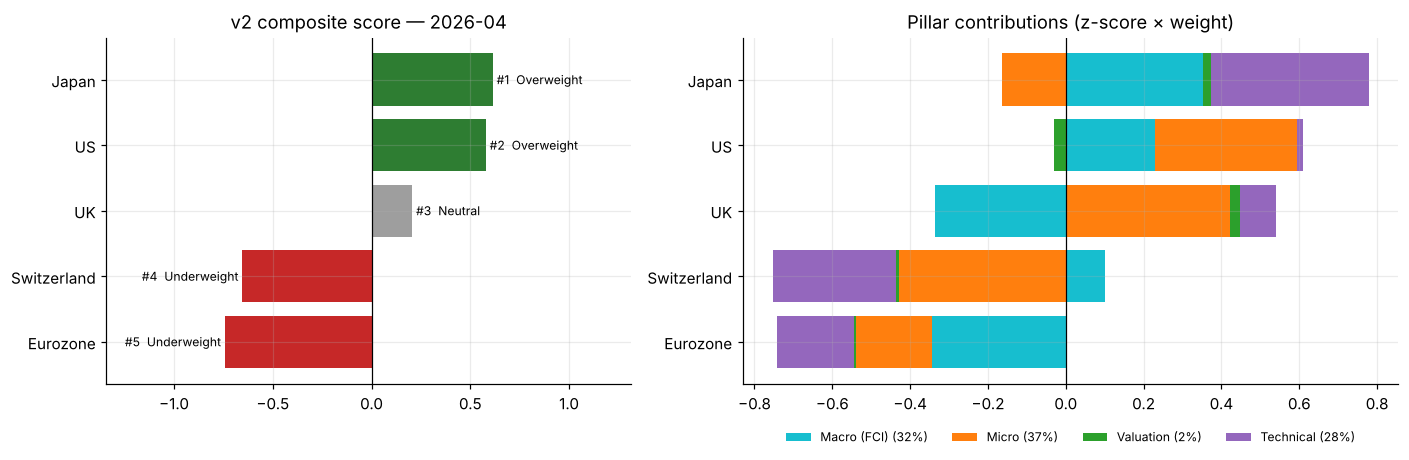

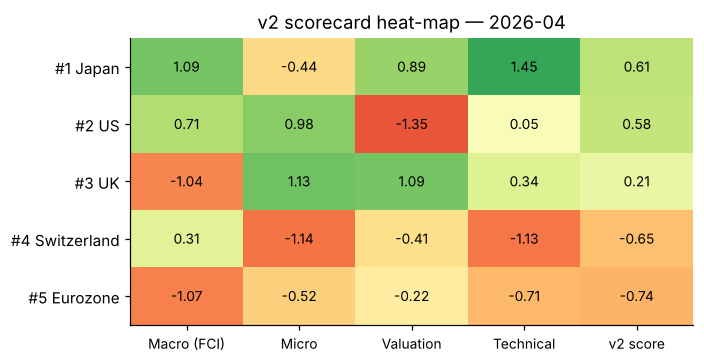

In [14]:
STANCE = {1: 'Overweight', 2: 'Overweight', 3: 'Neutral', 4: 'Underweight', 5: 'Underweight'}
rk = lambda name: COMPS[name].rank(axis=1, ascending=False)
wk_now = WTS[HEAD].loc[AS_OF]
keys = SPECS[HEAD][0]
cur = pd.DataFrame({'Macro (FCI)': Z['fci'].loc[AS_OF], 'Micro': Z['micro'].loc[AS_OF], 'Valuation': Z['val'].loc[AS_OF], 'Technical': Z['tech'].loc[AS_OF]})
cur['v2 score'] = COMPS[HEAD].loc[AS_OF]; cur['v2 rank'] = rk(HEAD).loc[AS_OF].astype(int); cur['v2 stance'] = cur['v2 rank'].map(STANCE)
cur['v1 rank'] = rk(V1).loc[AS_OF].astype(int); cur['v1 stance'] = cur['v1 rank'].map(STANCE)
cur = cur.sort_values('v2 rank'); display(cur)
print('v2 pillar weights at', AS_OF); display(wk_now.rename({'fci': 'Macro (FCI)', 'micro': 'Micro', 'val': 'Valuation', 'tech': 'Technical'}).to_frame('weight').T.style.format('{:.0%}'))

PCOL = {'Macro (FCI)': '#17becf', 'Micro': '#ff7f0e', 'Valuation': '#2ca02c', 'Technical': '#9467bd'}
pill = ['Macro (FCI)', 'Micro', 'Valuation', 'Technical']; wmap = dict(zip(pill, [wk_now[k] for k in keys]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1, 1.25]})
c2 = cur.sort_values('v2 score')
ax[0].barh(c2.index, c2['v2 score'], color=['#2e7d32' if s == 'Overweight' else '#c62828' if s == 'Underweight' else '#9e9e9e' for s in c2['v2 stance']])
for i, (idx, rw) in enumerate(c2.iterrows()):
    ax[0].text(rw['v2 score'] + (0.02 if rw['v2 score'] >= 0 else -0.02), i, f"#{rw['v2 rank']}  {rw['v2 stance']}", va='center', ha='left' if rw['v2 score'] >= 0 else 'right', fontsize=8)
ax[0].axvline(0, color='k', lw=.8); ax[0].set_title(f'v2 composite score — {AS_OF}'); ax[0].set_xlim(c2['v2 score'].min() - .6, c2['v2 score'].max() + .7)
contrib = pd.DataFrame({p: cur[p] * wmap[p] for p in pill}).loc[c2.index]; pos = np.zeros(len(contrib)); neg = np.zeros(len(contrib))
for p in pill:
    v = contrib[p].values; b = np.where(v >= 0, pos, neg)
    ax[1].barh(contrib.index, v, left=b, color=PCOL[p], label=f'{p} ({wmap[p]:.0%})'); pos = pos + np.where(v >= 0, v, 0); neg = neg + np.where(v < 0, v, 0)
ax[1].axvline(0, color='k', lw=.8); ax[1].set_title('Pillar contributions (z-score × weight)'); ax[1].legend(fontsize=8, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout(); plt.savefig(CH/'fig_v2_current_ranking.png', dpi=200, bbox_inches='tight'); plt.show()

fig, a = plt.subplots(figsize=(6.5, 3.4)); hm = cur[pill + ['v2 score']]
a.imshow(hm.values, cmap='RdYlGn', vmin=-2, vmax=2, aspect='auto'); a.set_xticks(range(hm.shape[1])); a.set_xticklabels(hm.columns, fontsize=9)
a.set_yticks(range(len(hm))); a.set_yticklabels([f'#{r} {i}' for i, r in zip(hm.index, cur['v2 rank'])])
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]): a.text(j, i, f'{hm.values[i, j]:.2f}', ha='center', va='center', fontsize=9)
a.grid(False); a.set_title(f'v2 scorecard heat-map — {AS_OF}'); plt.tight_layout(); plt.savefig(CH/'fig_v2_scorecard_heatmap.png', dpi=200, bbox_inches='tight'); plt.show()

## 9. Results summary

In [15]:
g = lambda sp, s, b, h, col: STATS[(STATS.Spec == sp) & (STATS.Strategy == s) & (STATS.Basis == b) & (STATS['H (M)'] == h)][col].iloc[0]
A = 'A. Score-weighted L/S'; ACT = 'B. Top-2 minus EW benchmark (active)'
pc = PP_comp[(PP_comp['Horizon (M)'] == 3) & (PP_comp.Basis == 'USD')].set_index('Signal')
pf = PP_single[(PP_single['Horizon (M)'] == 3) & (PP_single.Basis == 'USD')].set_index('Signal')
pm = PERM[(PERM.Basis == 'USD')].set_index('Spec')
top, bot = cur.index[:2].tolist(), cur.index[-2:].tolist()
md = f"""
**v2 current view ({AS_OF}):** Overweight **{', '.join(top)}** · Neutral **{cur.index[2]}** · Underweight **{', '.join(bot)}**.

**FCI vs PMI (USD, 3M IC):** FCI {pf.loc[PILLARS['fci'], 'Mean IC']:+.3f} (t {pf.loc[PILLARS['fci'], 'IC t-stat (NW)']:+.2f}) vs PMI {pf.loc[PILLARS['pmi'], 'Mean IC']:+.3f} (t {pf.loc[PILLARS['pmi'], 'IC t-stat (NW)']:+.2f}).
**Composite IC (USD, 3M):** v1 {pc.loc[V1, 'Mean IC']:+.3f} → v2 {pc.loc[HEAD, 'Mean IC']:+.3f} (NW t {pc.loc[HEAD, 'IC t-stat (NW)']:+.2f}, perm p {pc.loc[HEAD, 'Perm p-value (1-sided)']:.3f}).

**Backtest {bt_start} → {bt_end} (gross, H=3, USD):** v1 L/S Sharpe {g(V1, A, 'USD', 3, 'Sharpe'):.2f} → **v2 {g(HEAD, A, 'USD', 3, 'Sharpe'):.2f}**
(ann. return {g(V1, A, 'USD', 3, 'Ann. return'):.1%} → {g(HEAD, A, 'USD', 3, 'Ann. return'):.1%}; max DD {g(V1, A, 'USD', 3, 'Max drawdown'):.1%} → {g(HEAD, A, 'USD', 3, 'Max drawdown'):.1%}); local Sharpe {g(V1, A, 'local', 3, 'Sharpe'):.2f} → {g(HEAD, A, 'local', 3, 'Sharpe'):.2f}.
Permutation p for the v2 L/S Sharpe (USD): {pm.loc[HEAD, 'Perm p (1-sided)']:.3f} (v1: {pm.loc[V1, 'Perm p (1-sided)']:.3f}). Active top-2 vs EW (USD): IR {g(V1, ACT, 'USD', 3, 'Info ratio'):.2f} → {g(HEAD, ACT, 'USD', 3, 'Info ratio'):.2f}.
"""
display(Markdown(md))


**v2 current view (2026-04):** Overweight **Japan, US** · Neutral **UK** · Underweight **Switzerland, Eurozone**.

**FCI vs PMI (USD, 3M IC):** FCI +0.069 (t +1.41) vs PMI -0.049 (t -1.15).
**Composite IC (USD, 3M):** v1 +0.013 → v2 +0.069 (NW t +1.37, perm p 0.083).

**Backtest 2010-12 → 2026-04 (gross, H=3, USD):** v1 L/S Sharpe 0.05 → **v2 0.18**
(ann. return 0.1% → 1.1%; max DD -26.9% → -21.8%); local Sharpe 0.21 → 0.28.
Permutation p for the v2 L/S Sharpe (USD): 0.237 (v1: 0.431). Active top-2 vs EW (USD): IR -0.19 → 0.21.


### Honest read-out (static commentary written after inspecting the tables above)
* **C1 (PMI → FCI) helps.** FCI has a positive IC in all four cases (local/USD × 3M/6M; t = 1.0–2.2; permutation p 0.04–0.15) where PMI was negative in all four. Caveat: FCI was chosen *after* PMI failed.
* **C2 (walk-forward IC weights) did not help.** The pre-declared headline S3 is *weaker* than S1 (FCI + equal weights): L/S USD Sharpe 0.18 vs 0.35, and 0.07 vs 0.30 on the months where IC weights are active.
  Weights chase what worked recently (Micro 37–42%) and cut Valuation to ~2% after its IC turned negative in the 2nd half — the composite adapts slowly and adds noise.
* **Pre-declared v2 (S3) vs v1:** better (composite IC +0.013 → +0.069; Sharpe 0.05 → 0.18; active IR −0.19 → +0.21), but the L/S Sharpe permutation p-value is **0.24 (USD)** → **not distinguishable from luck**.
* **Selection caution:** S1 looks best (p ≈ 0.07–0.08) but was identified after the fact among 4 specifications; a simple ×4 adjustment puts it around 0.3. It is shown for transparency, **not** swapped in as the headline.
* **Fragility:** S3 Sharpe is +0.41 in the 1st half vs −0.05 in the 2nd; dropping one market at a time moves Sharpe between −0.03 (ex-US) and +0.63 (ex-Japan).
* **What is stable:** across all four specifications **Switzerland and Eurozone rank in the bottom two** and Japan is in the top two in three of four (UK/US swap places). The *direction* of the call is robust; the *size* of any alpha is not demonstrated.
* **No untouched OOS exists** (v2 was designed after viewing v1 on the same data). Treat all v2 statistics as exploratory.

## 10. Export CSVs

In [16]:
inp = []
for c in COUNTRIES:
    d = pd.DataFrame({'date': PE.index.to_timestamp('M'), 'country': c, 'fwd_pe': PE[c].values, 'fwd_eps': EPS[c].values, 'pmi': PMI[c].values,
                      'fci_raw': FCI_RAW[c].values, 'fci_oriented_easing': FCI_E[c].values, 'fx_usd_per_local': FX[c].values,
                      'implied_price_local': PX[c].values, 'implied_price_usd': PX_USD[c].values}).dropna(subset=['fwd_pe', 'fwd_eps'])
    inp.append(d)
pd.concat(inp).to_csv(DATA/'scorecard_input_monthly_v2.csv', index=False)

o = []
for c in COUNTRIES:
    d = pd.DataFrame({'date': SIG_IDX.to_timestamp('M'), 'country': c})
    for k in PILLARS: d[f'raw_{k}'] = RAW_SIG[k].loc[SIG_IDX, c].values
    for k in PILLARS: d[f'z_{k}'] = Z[k][c].values
    for k in SPECS[HEAD][0]: d[f'wf_weight_{k}'] = WTS[HEAD][k].values
    for name in SPECS:
        tag = name.split(':')[0].split()[0]; d[f'score_{tag}'] = COMPS[name][c].values; d[f'rank_{tag}'] = rk(name).loc[SIG_IDX, c].astype(int).values
    d['v2_stance'] = d['rank_S3'].map(STANCE)
    for (basis, h), f in fwd.items(): d[f'fwd_{h}m_ret_{basis}'] = f.loc[SIG_IDX, c].values
    o.append(d)
pd.concat(o).to_csv(OUT/'scorecard_monthly_scores_v2.csv', index=False)
cur.reset_index(names='country').to_csv(OUT/'current_ranking_v2.csv', index=False)
pd.concat([PP_single, PP_comp]).to_csv(OUT/'predictive_power_v2.csv', index=False)
STATS.to_csv(OUT/'backtest_stats_v2.csv', index=False)
spec_table().to_csv(OUT/'spec_comparison_full.csv'); spec_table(WF_START + 1).to_csv(OUT/'spec_comparison_wf_window.csv'); PERM.to_csv(OUT/'sharpe_permutation_test.csv', index=False)
bt_out = pd.concat({f'{n.split(":")[0].split()[0]}_{b}_H{h}': v for (n, b, h), v in BT.items()}, axis=1); bt_out.index = bt_out.index.to_timestamp('M')
bt_out.to_csv(OUT/'backtest_monthly_returns_v2.csv')
print('Saved:', *[p.relative_to(ROOT).as_posix() for p in sorted(list(OUT.glob('*.csv')) + [DATA/'scorecard_input_monthly_v2.csv'])], sep='\n  ')

Saved:
  data/scorecard_input_monthly_v2.csv
  output/v2/backtest_monthly_returns_v2.csv
  output/v2/backtest_stats_v2.csv
  output/v2/current_ranking_v2.csv
  output/v2/predictive_power_v2.csv
  output/v2/scorecard_monthly_scores_v2.csv
  output/v2/sharpe_permutation_test.csv
  output/v2/spec_comparison_full.csv
  output/v2/spec_comparison_wf_window.csv
